IoT Sensor Data Validator Project

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 

warnings.filterwarnings('ignore')

Load Dataset


In [2]:
df = pd.read_csv('Data\iot_telemetry_data.csv')

Data cleaning

In [4]:
df.head()

,ts,device,co,humidity,light,lpg,motion,smoke,temp
0,1.594512e+09,b8:27:eb:bf:9d:51,0.004956,51.000000,False,0.007651,False,0.020411,22.700000
1,1.594512e+09,00:0f:00:70:91:0a,0.002840,76.000000,False,0.005114,False,0.013275,19.700001
2,1.594512e+09,b8:27:eb:bf:9d:51,0.004976,50.900000,False,0.007673,False,0.020475,22.600000
3,1.594512e+09,1c:bf:ce:15:ec:4d,0.004403,76.800003,True,0.007023,False,0.018628,27.000000
4,1.594512e+09,b8:27:eb:bf:9d:51,0.004967,50.900000,False,0.007664,False,0.020448,22.600000


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 405184 entries, 0 to 405183
Data columns (total 9 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   ts        405184 non-null  float64
 1   device    405184 non-null  str    
 2   co        405184 non-null  float64
 3   humidity  405184 non-null  float64
 4   light     405184 non-null  bool   
 5   lpg       405184 non-null  float64
 6   motion    405184 non-null  bool   
 7   smoke     405184 non-null  float64
 8   temp      405184 non-null  float64
dtypes: bool(2), float64(6), str(1)
memory usage: 29.0 MB


In [5]:
df.shape

(405184, 9)

In [6]:
df.isnull().sum()

ts          0
device      0
co          0
humidity    0
light       0
lpg         0
motion      0
smoke       0
temp        0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(13)

In [8]:
df = df.drop_duplicates()

In [9]:
df.shape

(405171, 9)

Exploratory Data Analysis

In [10]:
print("Unique Devices:", df["device"].nunique())

print("\nDevice-wise Record Count:")
print(df["device"].value_counts())

Unique Devices: 3

Device-wise Record Count:
device
b8:27:eb:bf:9d:51    187443
00:0f:00:70:91:0a    111815
1c:bf:ce:15:ec:4d    105913
Name: count, dtype: int64


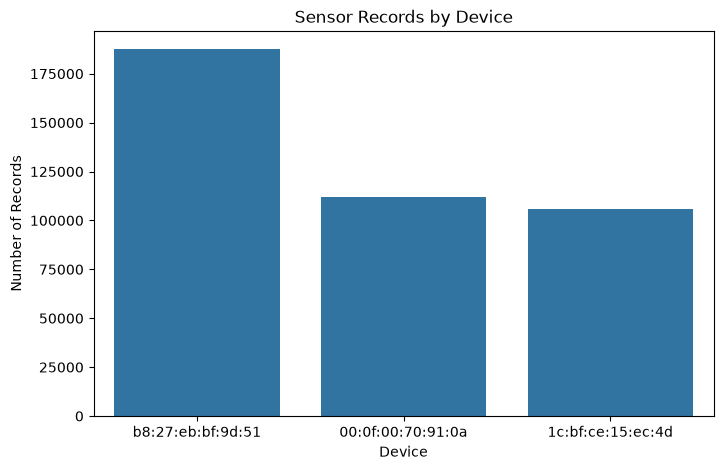

In [11]:

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="device")

plt.title("Sensor Records by Device")
plt.xlabel("Device")
plt.ylabel("Number of Records")

plt.show()

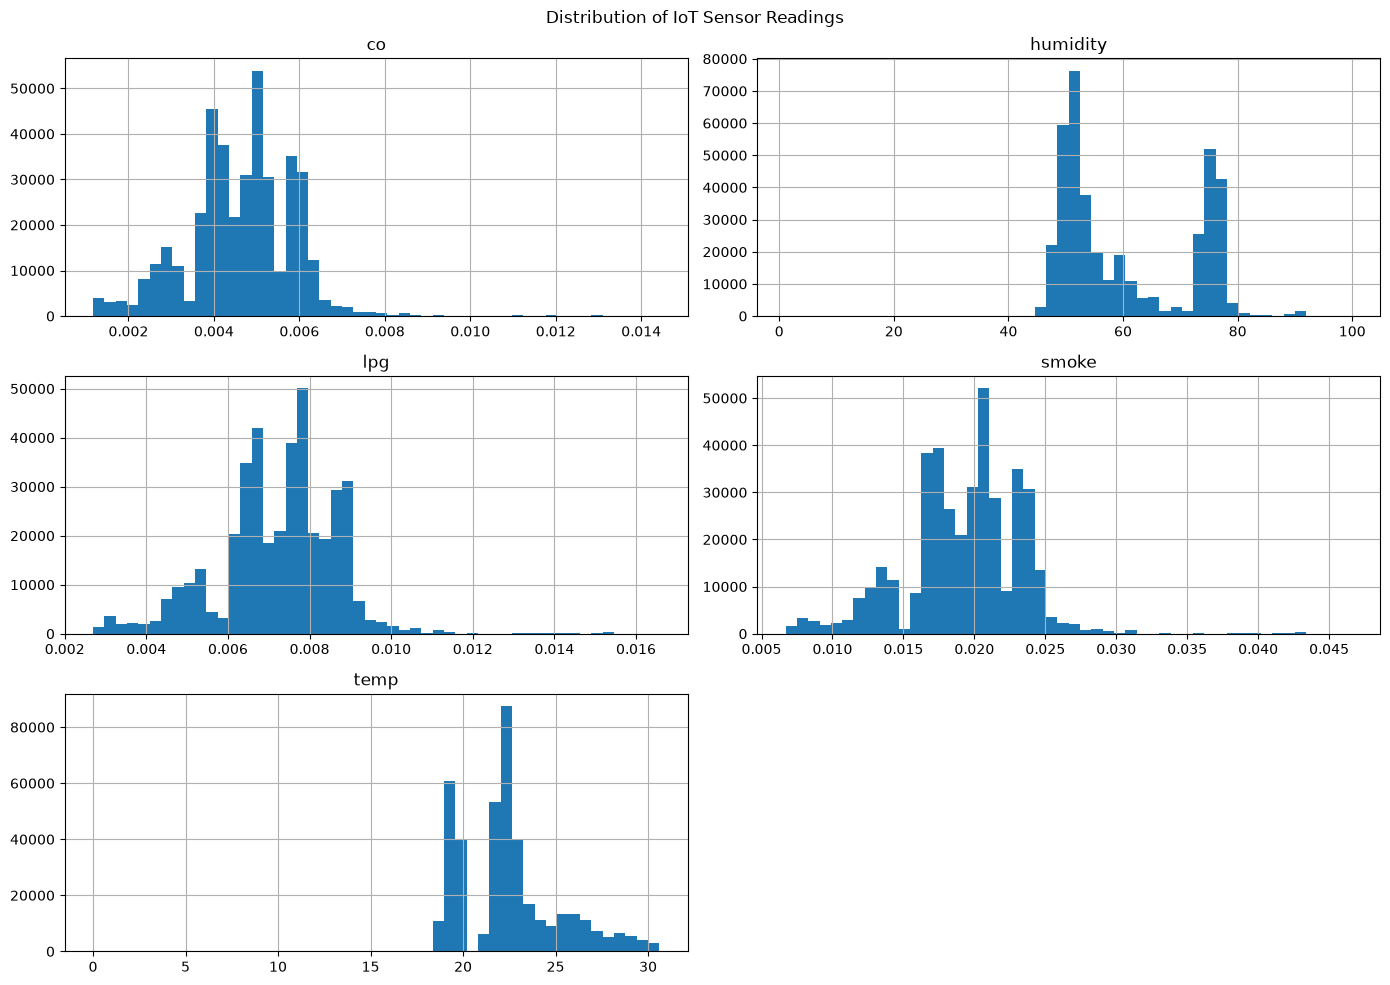

In [12]:
sensor_cols = ["co", "humidity", "lpg", "smoke", "temp"]

df[sensor_cols].hist(
    figsize=(14, 10),
    bins=50
)

plt.suptitle("Distribution of IoT Sensor Readings")
plt.tight_layout()
plt.show()

In [13]:
display(df[sensor_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
co,405171.0,0.004639,0.001250,0.001171,0.003919,0.004812,0.005409,0.014420
humidity,405171.0,60.511817,11.366504,1.100000,51.000000,54.900000,74.300003,99.900002
lpg,405171.0,0.007237,0.001444,0.002693,0.006456,0.007489,0.008150,0.016567
smoke,405171.0,0.019264,0.004086,0.006692,0.017024,0.019950,0.021838,0.046590
temp,405171.0,22.453958,2.698370,0.000000,19.900000,22.200000,23.600000,30.600000


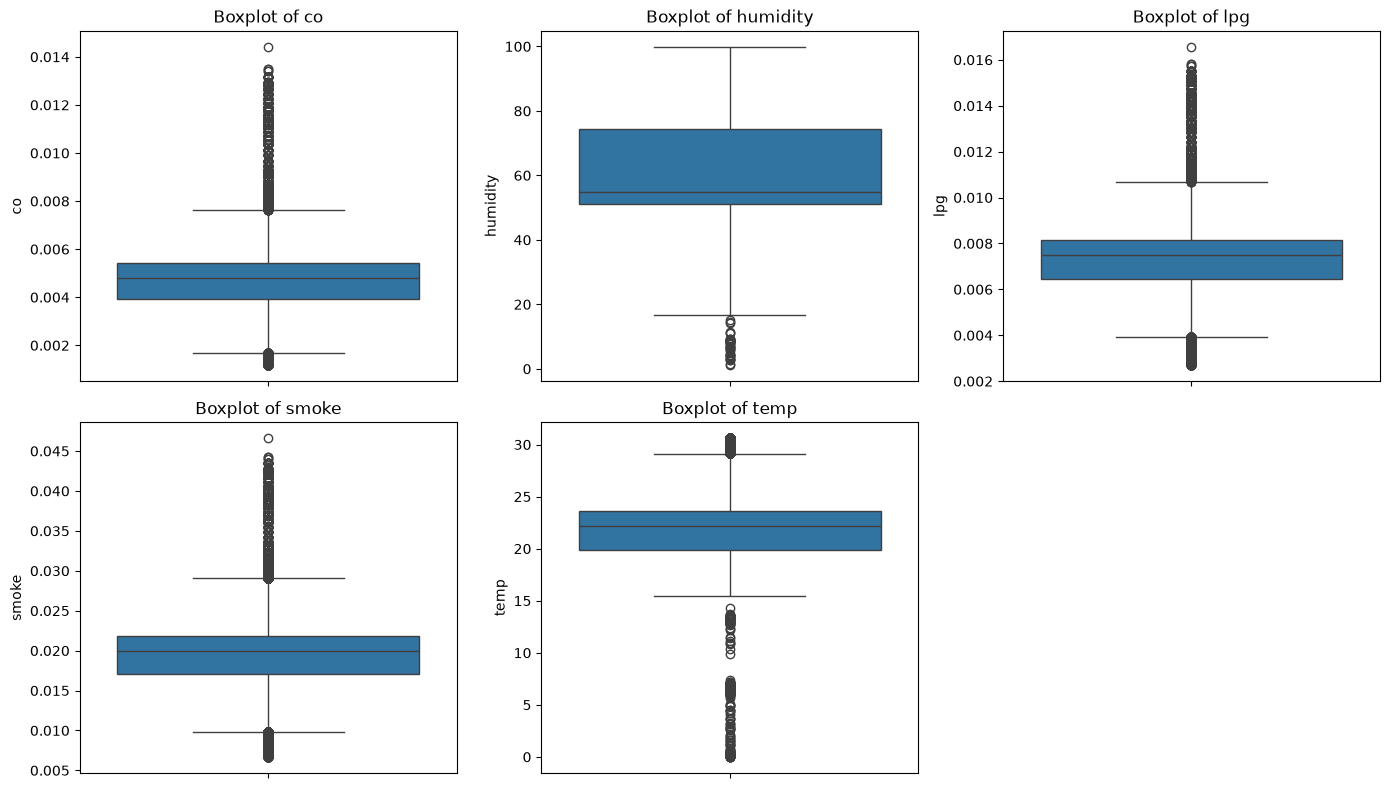

In [ ]:
sensor_cols = ["co", "humidity", "lpg", "smoke", "temp"]
plt.figure(figsize=(14, 8))

for i, col in enumerate(sensor_cols, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col])
    plt.title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

In [15]:
print("Temperature = 0:", (df["temp"] == 0).sum())

print("\nTemperature below 10:")
print((df["temp"] < 10).sum())

print("\nTemperature by device:")
print(
    df.groupby("device")["temp"]
    .agg(["min", "max", "mean", "median"])
)

Temperature = 0: 7

Temperature below 10:
232

Temperature by device:
                    min        max       mean  median
device                                               
00:0f:00:70:91:0a   0.0  20.200001  19.362552    19.4
1c:bf:ce:15:ec:4d   0.0  30.600000  26.025563    25.9
b8:27:eb:bf:9d:51  21.0  24.100000  22.279965    22.3


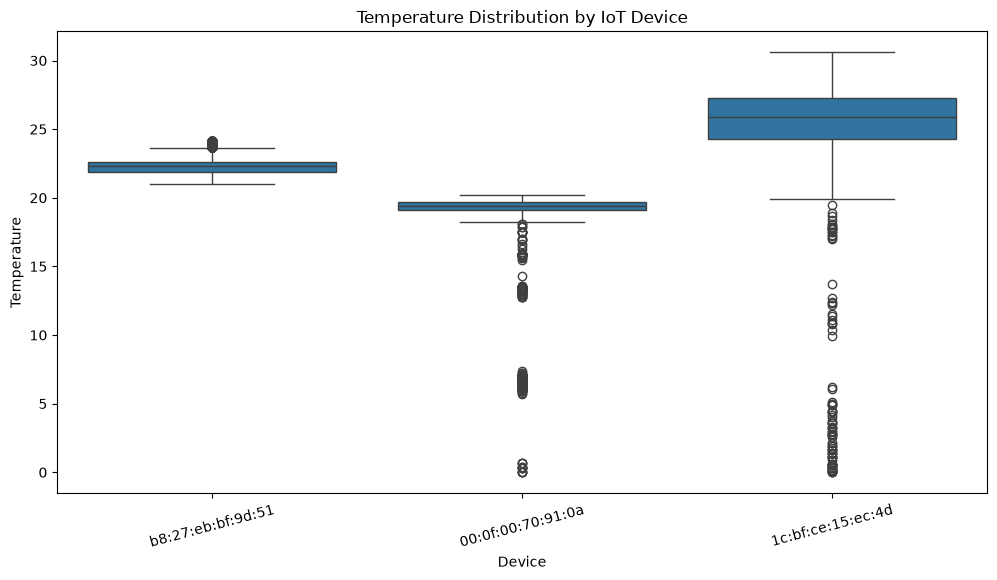

In [16]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=df, x="device", y="temp")

plt.title("Temperature Distribution by IoT Device")
plt.xlabel("Device")
plt.ylabel("Temperature")
plt.xticks(rotation=15)

plt.show()

In [17]:
print("Humidity below 20:", (df["humidity"] < 20).sum())

print("\nHumidity by device:")
display(
    df.groupby("device")["humidity"]
    .agg(["min", "max", "mean", "median"])
)

Humidity below 20: 47

Humidity by device:


,min,max,mean,median
device,,,,
00:0f:00:70:91:0a,1.1,99.900002,75.444361,75.400002
1c:bf:ce:15:ec:4d,1.6,92.000000,61.910021,59.599998
b8:27:eb:bf:9d:51,45.1,63.300000,50.814093,50.900000


EDA done

In [18]:
display(df["ts"].head())

0    1.594512e+09
1    1.594512e+09
2    1.594512e+09
3    1.594512e+09
4    1.594512e+09
Name: ts, dtype: float64

In [19]:
df["ts"] = pd.to_datetime(df["ts"], unit="s")

print(df["ts"].head())
print(df["ts"].dtype)

0   2020-07-12 00:01:34.385974646
1   2020-07-12 00:01:34.735567570
2   2020-07-12 00:01:38.073572874
3   2020-07-12 00:01:39.589145899
4   2020-07-12 00:01:41.761234999
Name: ts, dtype: datetime64[ns]
datetime64[ns]


In [20]:
df["hour"] = df["ts"].dt.hour
df["day"] = df["ts"].dt.day
df["day_of_week"] = df["ts"].dt.dayofweek

display(df[["ts", "hour", "day", "day_of_week"]].head())

,ts,hour,day,day_of_week
0,2020-07-12 00:01:34.385974646,0,12,6
1,2020-07-12 00:01:34.735567570,0,12,6
2,2020-07-12 00:01:38.073572874,0,12,6
3,2020-07-12 00:01:39.589145899,0,12,6
4,2020-07-12 00:01:41.761234999,0,12,6


In [21]:
df = pd.get_dummies(df, columns=["device"], dtype=int)

In [23]:
df.head()

,ts,co,humidity,light,lpg,motion,smoke,temp,hour,day,day_of_week,device_00:0f:00:70:91:0a,device_1c:bf:ce:15:ec:4d,device_b8:27:eb:bf:9d:51
0,2020-07-12 00:01:34.385974646,0.004956,51.000000,False,0.007651,False,0.020411,22.700000,0,12,6,0,0,1
1,2020-07-12 00:01:34.735567570,0.002840,76.000000,False,0.005114,False,0.013275,19.700001,0,12,6,1,0,0
2,2020-07-12 00:01:38.073572874,0.004976,50.900000,False,0.007673,False,0.020475,22.600000,0,12,6,0,0,1
3,2020-07-12 00:01:39.589145899,0.004403,76.800003,True,0.007023,False,0.018628,27.000000,0,12,6,0,1,0
4,2020-07-12 00:01:41.761234999,0.004967,50.900000,False,0.007664,False,0.020448,22.600000,0,12,6,0,0,1


In [22]:
X = df.drop(columns=["ts", "day"])

print(X.shape)
print(X.dtypes)

(405171, 12)
co                          float64
humidity                    float64
light                          bool
lpg                         float64
motion                         bool
smoke                       float64
temp                        float64
hour                          int32
day_of_week                   int32
device_00:0f:00:70:91:0a      int64
device_1c:bf:ce:15:ec:4d      int64
device_b8:27:eb:bf:9d:51      int64
dtype: object


IsolationForest Model


In [24]:
from sklearn.ensemble import IsolationForest

model = IsolationForest(
    n_estimators=100,
    contamination=0.01,
    random_state=42,
    n_jobs=-1
)

model.fit(X)

df["anomaly"] = model.predict(X)

df["anomaly"] = df["anomaly"].map({
    1: "Normal",
    -1: "Anomaly"
})

print(df["anomaly"].value_counts())

anomaly
Normal     401122
Anomaly      4049
Name: count, dtype: int64


In [25]:
anomalies = df[df["anomaly"] == "Anomaly"]

display(anomalies.head(10))

,ts,co,humidity,light,lpg,motion,smoke,temp,hour,day,day_of_week,device_00:0f:00:70:91:0a,device_1c:bf:ce:15:ec:4d,device_b8:27:eb:bf:9d:51,anomaly
46534,2020-07-12 22:08:36.579161882,0.006251,74.400002,True,0.009050,False,0.024422,18.799999,22,12,6,1,0,0,Anomaly
46538,2020-07-12 22:08:44.664883375,0.006251,74.300003,True,0.009050,False,0.024422,18.799999,22,12,6,1,0,0,Anomaly
46541,2020-07-12 22:08:49.543100119,0.006251,74.199997,True,0.009050,False,0.024422,18.799999,22,12,6,1,0,0,Anomaly
46546,2020-07-12 22:08:58.165697098,0.006251,74.099998,True,0.009050,False,0.024422,18.799999,22,12,6,1,0,0,Anomaly
46549,2020-07-12 22:09:02.514223576,0.006316,74.099998,True,0.009117,False,0.024617,18.799999,22,12,6,1,0,0,Anomaly
46552,2020-07-12 22:09:06.855581284,0.006251,74.199997,True,0.009050,False,0.024422,18.799999,22,12,6,1,0,0,Anomaly
46555,2020-07-12 22:09:12.889411688,0.006251,74.300003,True,0.009050,False,0.024422,18.799999,22,12,6,1,0,0,Anomaly
46560,2020-07-12 22:09:18.301384687,0.006251,74.300003,True,0.009050,False,0.024422,18.799999,22,12,6,1,0,0,Anomaly
46563,2020-07-12 22:09:25.863647699,0.006381,74.300003,True,0.009185,False,0.024813,18.799999,22,12,6,1,0,0,Anomaly
46567,2020-07-12 22:09:31.804810286,0.006251,74.400002,True,0.009050,False,0.024422,18.799999,22,12,6,1,0,0,Anomaly


In [26]:
df["light"] = df["light"].astype(int)
df["motion"] = df["motion"].astype(int)

In [27]:
print("Anomaly percentage:")
print((df["anomaly"] == "Anomaly").mean() * 100)

print("\nAnomaly sensor statistics:")
display(
    df[df["anomaly"] == "Anomaly"][
        ["co", "humidity", "lpg", "smoke", "temp"]
    ].describe()
)

Anomaly percentage:
0.9993311466022987

Anomaly sensor statistics:


,co,humidity,lpg,smoke,temp
count,4049.000000,4049.000000,4049.000000,4049.000000,4049.000000
mean,0.008520,71.800469,0.011183,0.030693,19.631638
std,0.002660,6.836658,0.002740,0.007903,2.917292
min,0.001171,5.700000,0.002693,0.006692,0.400000
25%,0.007681,73.500000,0.010504,0.028637,18.600000
50%,0.008437,73.900002,0.011243,0.030792,18.799999
75%,0.010365,74.300003,0.013047,0.036099,19.000000
max,0.014420,99.900002,0.016567,0.046590,30.100000


In [28]:
df["anomaly_score"] = model.decision_function(X)

anomalies = df[df["anomaly"] == "Anomaly"].sort_values(
    "anomaly_score"
)

display(
    anomalies[
        ["ts", "co", "humidity", "lpg", "smoke", "temp",
         "anomaly_score", "anomaly"]
    ].head(10)
)

,ts,co,humidity,lpg,smoke,temp,anomaly_score,anomaly
49257,2020-07-12 23:25:40.849174738,0.013180,73.800003,0.015524,0.043461,5.8,-0.098753,Anomaly
49065,2020-07-12 23:20:14.232759953,0.012659,74.400002,0.015077,0.042128,15.5,-0.096743,Anomaly
48744,2020-07-12 23:11:10.981049538,0.012659,73.900002,0.015077,0.042128,17.0,-0.094882,Anomaly
49696,2020-07-12 23:37:48.735294819,0.012659,74.099998,0.015077,0.042128,18.6,-0.090678,Anomaly
49736,2020-07-12 23:38:52.782071352,0.012863,74.099998,0.015253,0.042653,18.6,-0.090678,Anomaly
49732,2020-07-12 23:38:46.821512461,0.012863,74.099998,0.015253,0.042653,18.6,-0.090678,Anomaly
49715,2020-07-12 23:38:21.306691885,0.012659,74.099998,0.015077,0.042128,18.6,-0.090678,Anomaly
49713,2020-07-12 23:38:16.418564081,0.012863,74.099998,0.015253,0.042653,18.6,-0.090678,Anomaly
49743,2020-07-12 23:39:05.237454891,0.012863,74.099998,0.015253,0.042653,18.6,-0.090678,Anomaly
49642,2020-07-12 23:36:14.745428562,0.012863,74.199997,0.015253,0.042653,18.6,-0.090678,Anomaly


In [29]:
print(df.columns.tolist())
print(df[["co", "humidity", "lpg", "smoke", "temp",
          "anomaly_score", "anomaly"]].head())

['ts', 'co', 'humidity', 'light', 'lpg', 'motion', 'smoke', 'temp', 'hour', 'day', 'day_of_week', 'device_00:0f:00:70:91:0a', 'device_1c:bf:ce:15:ec:4d', 'device_b8:27:eb:bf:9d:51', 'anomaly', 'anomaly_score']
         co   humidity       lpg     smoke       temp  anomaly_score anomaly
0  0.004956  51.000000  0.007651  0.020411  22.700000       0.142863  Normal
1  0.002840  76.000000  0.005114  0.013275  19.700001       0.111781  Normal
2  0.004976  50.900000  0.007673  0.020475  22.600000       0.145071  Normal
3  0.004403  76.800003  0.007023  0.018628  27.000000       0.075045  Normal
4  0.004967  50.900000  0.007664  0.020448  22.600000       0.144332  Normal


In [30]:
# Basic sensor validation rules
df["rule_invalid"] = (
    (df["humidity"] < 0) | (df["humidity"] > 100) |
    (df["temp"] < 0) | (df["temp"] > 50) |
    (df["co"] < 0) |
    (df["lpg"] < 0) |
    (df["smoke"] < 0)
)

print(df["rule_invalid"].value_counts())

rule_invalid
False    405171
Name: count, dtype: int64


In [31]:
df["validation_result"] = "Valid"

df.loc[df["anomaly"] == "Anomaly", "validation_result"] = (
    "Suspicious"
)

df.loc[df["rule_invalid"], "validation_result"] = (
    "Invalid"
)

print(df["validation_result"].value_counts())

validation_result
Valid         401122
Suspicious      4049
Name: count, dtype: int64
